# TP6. Géométrie du plan

Carnet de travail. L'énoncé complet, avec les corrigés, est sur le site :
https://cours.gclab.fr/outils-fondamentaux/tp6-geometrie-plan/

Exécutez une cellule avec Maj+Entrée. **Pensez à télécharger ce carnet avant de partir** : menu File, puis Download.


**Version complétée avec assistance IA.** Solutions et explications adaptées des [corrigés de Christophe Guyeux](https://cours.gclab.fr/outils-fondamentaux/tp6-geometrie-plan/), sous licence [CC BY-NC-SA 4.0](https://creativecommons.org/licenses/by-nc-sa/4.0/). Les blocs du cours nécessaires aux exercices sont ajoutés. Exécuter les cellules dans l’ordre. Les temps mesurés dépendent de la machine. Relire les réponses et indiquer dans le README les vérifications réalisées personnellement.

**Rappel du cours / préparation pour la suite**

In [1]:
A = (1, 2)
B = (4, 6)
AB = (B[0] - A[0], B[1] - A[1])
print(AB)

(3, 4)


## Exercice 1.1 : la boîte à outils

Écrivez `vecteur(A, B)`, `produit_scalaire(u, v)`, `norme(u)` et `angle(u, v)`, ce
dernier en degrés.

**Résultat attendu :** `norme((3, 4))` vaut `5.0`, `produit_scalaire((1, 2), (3, 4))`
vaut `11`, `angle((1, 0), (1, 1))` vaut `45.0` à l'arrondi près, et
`angle((1, 0), (0, 1))` vaut `90.0`.


In [2]:
import math

def vecteur(A, B):

    return (B[0] - A[0], B[1] - A[1])

def produit_scalaire(u, v):
    return u[0] * v[0] + u[1] * v[1]

def norme(u):
    return math.hypot(u[0], u[1])

def angle(u, v):

    cosinus = produit_scalaire(u, v) / (norme(u) * norme(v))
    cosinus = max(-1.0, min(1.0, cosinus))
    return math.degrees(math.acos(cosinus))

print(norme((3, 4)), produit_scalaire((1, 2), (3, 4)))
print(angle((1, 0), (1, 1)), angle((1, 0), (0, 1)))
print(angle((2, 0), (2, 0)))

5.0 11
45.00000000000001 90.0
0.0


Deux détails de professionnel. math.hypot(x, y) calcule
\( \sqrt{x^{2} + y^{2}} \) sans faire déborder les carrés quand x et y sont
grands, là où math.sqrt(x * x + y * y) renverrait l'infini au delà de
\( 10^{154} \). Et la ligne max(-1.0, min(1.0, cosinus)) protège acos : par
arrondi, le quotient peut valoir 1.0000000000000002 pour deux vecteurs
parallèles, et acos refuserait alors de répondre. Les flottants du TP1 sont là,
même en géométrie. Notez enfin que angle((1, 0), (1, 1)) n'affiche pas
exactement 45.0 : là encore, un arrondi.

## Exercice 1.2 : la distance d'un point à une droite

La distance du point $P$ à la droite $(AB)$ vaut
$\dfrac{|\vec{AB} \times \vec{AP}|}{\|\vec{AB}\|}$, où $\times$ désigne le
**déterminant** $u_x v_y - u_y v_x$, que l'étape suivante interprète. Écrivez
`determinant(u, v)` puis `distance_point_droite(P, A, B)`.

**Résultat attendu :** la distance de l'origine à la droite passant par $(0, 1)$ et
$(1, 0)$ vaut $\sqrt{2}/2 \approx 0{,}7071$, et celle de $(3, 4)$ à l'axe des
abscisses vaut `4.0`.


In [3]:
def determinant(u, v):

    return u[0] * v[1] - u[1] * v[0]

def distance_point_droite(P, A, B):
    AB = vecteur(A, B)
    AP = vecteur(A, P)
    return abs(determinant(AB, AP)) / norme(AB)

print(distance_point_droite((0, 0), (0, 1), (1, 0)), math.sqrt(2) / 2)
print(distance_point_droite((3, 4), (0, 0), (1, 0)))

0.7071067811865475 0.7071067811865476
4.0


La formule vient de l'aire : le déterminant est l'aire du parallélogramme construit
sur \( \vec{AB} \) et \( \vec{AP} \), et cette aire vaut aussi base fois hauteur,
la base étant \( \|\vec{AB}\| \) et la hauteur la distance cherchée.

## Exercice 2.1 : à gauche ou à droite ?

Écrivez `orientation(A, B, C)` qui renvoie `1` si le trajet $A \to B \to C$ tourne
à gauche, `-1` s'il tourne à droite, `0` si les trois points sont alignés.

**Résultat attendu :** `orientation((0, 0), (1, 0), (1, 1))` vaut `1`,
`orientation((0, 0), (1, 0), (1, -1))` vaut `-1`, et
`orientation((0, 0), (1, 1), (2, 2))` vaut `0`.


In [4]:
def orientation(A, B, C):

    d = determinant(vecteur(A, B), vecteur(A, C))
    if d > 0:
        return 1
    if d < 0:
        return -1
    return 0

print(orientation((0, 0), (1, 0), (1, 1)))
print(orientation((0, 0), (1, 0), (1, -1)))
print(orientation((0, 0), (1, 1), (2, 2)))

1
-1
0


Le cas 0 est fragile avec des flottants : trois points « presque » alignés
donneront un déterminant de l'ordre de \( 10^{-16} \), donc 1 ou -1 au
hasard. C'est le problème de l'exercice 2.2 du TP1, et la bonne réponse est la
même : comparer à une tolérance, pas à zéro. Les bibliothèques de géométrie
sérieuses vont plus loin encore, et calculent ce signe en arithmétique exacte,
avec des Fraction ou des entiers, parce qu'un signe faux fait planter tout ce
qui suit.

## Exercice 2.2 : l'aire d'un polygone

Un polygone est une liste de sommets dans l'ordre. Son aire vaut la moitié de la
valeur absolue de la somme des déterminants $x_i y_{i+1} - x_{i+1} y_i$ sur les
côtés consécutifs, le dernier sommet étant relié au premier : c'est la **formule du
lacet**. Écrivez `aire(polygone)`.

**Résultat attendu :** le carré unité a une aire de `1.0`, le triangle
$(0,0), (4,0), (0,3)$ une aire de `6.0`, et la maison du TP4,
`[(0, 0), (2, 0), (2, 1.5), (1, 2.5), (0, 1.5)]`, une aire de `4.0`.


In [5]:
def aire(polygone):

    somme = 0
    n = len(polygone)
    for i in range(n):
        x1, y1 = polygone[i]
        x2, y2 = polygone[(i + 1) % n]
        somme = somme + (x1 * y2 - x2 * y1)
    return abs(somme) / 2

carre = [(0, 0), (1, 0), (1, 1), (0, 1)]
triangle = [(0, 0), (4, 0), (0, 3)]
maison = [(0, 0), (2, 0), (2, 1.5), (1, 2.5), (0, 1.5)]
print(aire(carre), aire(triangle), aire(maison))

1.0 6.0 4.0


L'indice (i + 1) % n referme le polygone : le sommet qui suit le dernier est le
premier. Vérifiez la maison à la main : un rectangle de \( 2 \times 1{,}5 = 3 \)
surmonté d'un triangle de base 2 et de hauteur 1, soit \( 3 + 1 = 4 \). La formule
marche pour n'importe quel polygone sans croisement, convexe ou non, en une seule
boucle : c'est elle qu'utilisent les cadastres pour calculer la surface d'une
parcelle à partir des coordonnées de ses bornes.

Sans la valeur absolue, le signe dit dans quel sens les sommets sont parcourus :
positif dans le sens direct. Essayez maison[::-1].

## Exercice 3.1 : le test de croisement

Écrivez `se_coupent(A, B, C, D)` avec quatre appels à `orientation`. Ne traitez pas les
cas où trois points sont alignés : renvoyez `False`, et notez-le dans la docstring.

**Résultat attendu :** les diagonales du carré unité se coupent ; les segments
$[(0,0), (1, 0)]$ et $[(0, 1), (1, 1)]$, parallèles, ne se coupent pas ;
$[(0,0), (1,1)]$ et $[(2,2), (3,3)]$, alignés mais disjoints, non plus.


In [6]:
def se_coupent(A, B, C, D):

    o1 = orientation(A, B, C)
    o2 = orientation(A, B, D)
    o3 = orientation(C, D, A)
    o4 = orientation(C, D, B)
    return o1 * o2 < 0 and o3 * o4 < 0

print(se_coupent((0, 0), (1, 1), (0, 1), (1, 0)))
print(se_coupent((0, 0), (1, 0), (0, 1), (1, 1)))
print(se_coupent((0, 0), (1, 1), (2, 2), (3, 3)))

True
False
False


o1 * o2 < 0 dit que C et D sont de signes opposés par rapport à \( (AB) \).
Le produit est la manière la plus courte d'écrire « de signes contraires », déjà
employée dans la dichotomie du TP3.

## Exercice 3.2 : le point d'intersection

Quand les segments se coupent, on veut souvent le point. En écrivant
$A + t\,\vec{AB} = C + u\,\vec{CD}$, on obtient un système de deux équations à deux
inconnues $t$ et $u$, que les déterminants résolvent directement :
$t = \dfrac{\vec{AC} \times \vec{CD}}{\vec{AB} \times \vec{CD}}$ et
$u = \dfrac{\vec{AC} \times \vec{AB}}{\vec{AB} \times \vec{CD}}$. Écrivez
`intersection(A, B, C, D)` qui renvoie le point, ou `None` si les segments ne se
coupent pas.

**Résultat attendu :** les diagonales du carré de côté 2 se coupent en `(1.0, 1.0)`.


In [7]:
def intersection(A, B, C, D):

    AB = vecteur(A, B)
    CD = vecteur(C, D)
    denominateur = determinant(AB, CD)
    if denominateur == 0:
        return None            
    AC = vecteur(A, C)
    t = determinant(AC, CD) / denominateur
    u = determinant(AC, AB) / denominateur
    if 0 <= t <= 1 and 0 <= u <= 1:
        return (A[0] + t * AB[0], A[1] + t * AB[1])
    return None

print(intersection((0, 0), (2, 2), (0, 2), (2, 0)))
print(intersection((0, 0), (1, 0), (0, 1), (1, 1)))
print(intersection((0, 0), (1, 1), (2, 2), (3, 3)))

(1.0, 1.0)
None
None


C'est un système linéaire \( 2 \times 2 \), résolu par les formules de Cramer, qui
ne sont rien d'autre que le pivot de Gauss du TP4 écrit pour la taille 2. Le test
denominateur == 0 est encore une comparaison exacte de flottants : pour deux
segments presque parallèles, t et u seront énormes et le point renvoyé
n'aura aucun sens. Un programme robuste compare abs(denominateur) à une
tolérance, et les intersections presque parallèles sont la plaie de tous les
logiciels de CAO.

## Exercice 4.1 : le lancer de rayon

Écrivez `dedans(P, polygone)`. Pour chaque côté $[S_i S_{i+1}]$, le rayon le
traverse si les deux ordonnées encadrent celle de $P$ et si l'abscisse du point de
croisement, obtenue par interpolation, est à droite de $P$.

**Résultat attendu :** dans la maison, `(1, 1)` et `(1, 2.4)` sont dedans, `(3, 1)`
et `(0.2, 2.2)` sont dehors.


In [8]:
def dedans(P, polygone):

    x, y = P
    n = len(polygone)
    interieur = False
    for i in range(n):
        x1, y1 = polygone[i]
        x2, y2 = polygone[(i + 1) % n]
        if (y1 > y) != (y2 > y):
            x_croisement = x1 + (y - y1) * (x2 - x1) / (y2 - y1)
            if x < x_croisement:
                interieur = not interieur
    return interieur

for P in ((1, 1), (1, 2.4), (3, 1), (0.2, 2.2)):
    print(P, dedans(P, maison))

(1, 1) True
(1, 2.4) True
(3, 1) False
(0.2, 2.2) False


La condition (y1 > y) != (y2 > y) est le cœur de l'algorithme, et elle est plus
subtile qu'il n'y paraît : avec des inégalités strictes d'un côté et larges de
l'autre, un rayon qui passe exactement par un sommet compte le sommet pour un seul
des deux côtés qui s'y rejoignent, et non pour deux ou zéro. Sans cette précaution,
les sommets seraient une source inépuisable de résultats faux. Le point
(0.2, 2.2) est sous le toit mais hors du mur gauche : il faut un instant de
réflexion pour voir qu'il est bien dehors, et la machine ne se trompe pas.

## Exercice 4.2 : l'aire par le hasard

On peut estimer une aire sans formule : tirer des points au hasard dans un rectangle
qui contient la figure, compter ceux qui tombent dedans, et multiplier la proportion
par l'aire du rectangle. C'est la **méthode de Monte-Carlo**. Estimez ainsi l'aire de
la maison avec 200 000 points tirés dans le rectangle $[0, 2] \times [0, 2{,}5]$.

**Résultat attendu :** une valeur proche de `4.0`, à quelques centièmes près, et qui
change à chaque exécution si vous ne fixez pas la graine.


In [9]:
import random

random.seed(0)
tirages = 200_000
touches = 0
for _ in range(tirages):
    P = (random.uniform(0, 2), random.uniform(0, 2.5))
    if dedans(P, maison):
        touches = touches + 1

aire_rectangle = 2 * 2.5
print(aire_rectangle * touches / tirages)

3.994425


Deux cent mille tirages pour deux chiffres justes, contre une boucle de cinq
tours pour la formule du lacet : Monte-Carlo est une méthode lente, dont l'erreur
ne diminue que comme \( 1/\sqrt{N} \), il faut cent fois plus de points pour
gagner une décimale. Mais elle marche sur n'importe quelle figure dont on sait
seulement dire si un point est dedans, y compris en dimension 10 ou 1 000, là où
aucune formule n'existe. C'est ainsi que se calculent les intégrales de la
physique des particules et les prix des produits financiers.

**Rappel du cours / préparation pour la suite**

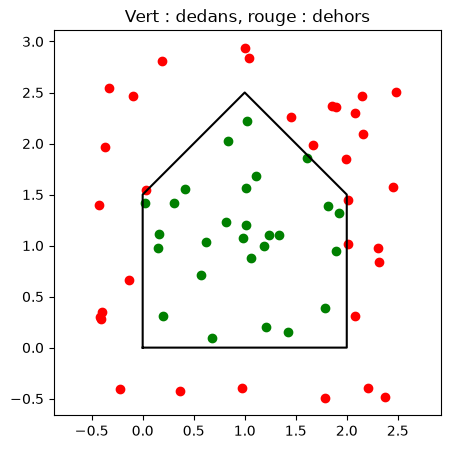

In [10]:
import matplotlib.pyplot as plt

def tracer_polygone(polygone, points=()):
    xs = [s[0] for s in polygone] + [polygone[0][0]]
    ys = [s[1] for s in polygone] + [polygone[0][1]]
    plt.figure(figsize=(5, 5))
    plt.plot(xs, ys, color="black")
    for P in points:
        couleur = "green" if dedans(P, polygone) else "red"
        plt.scatter([P[0]], [P[1]], color=couleur)
    plt.axis("equal")
    plt.title("Vert : dedans, rouge : dehors")
    plt.show()

random.seed(1)
nuage = [(random.uniform(-0.5, 2.5), random.uniform(-0.5, 3)) for _ in range(60)]
tracer_polygone(maison, nuage)

## Exercice 5.1 : un polygone qui n'est pas convexe

Construisez un polygone en forme de L ou d'étoile, non convexe, et vérifiez sur un
tracé que `dedans` et `aire` donnent des résultats corrects, y compris dans le creux.


4.7023
True True False


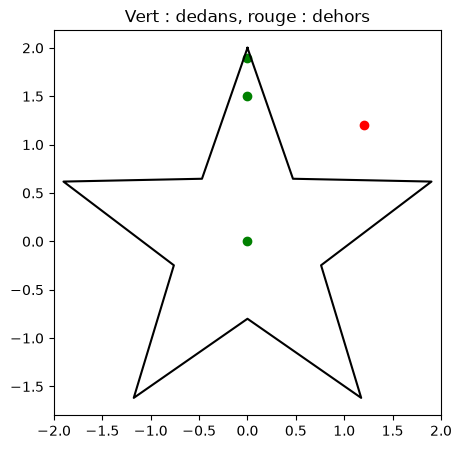

In [11]:
etoile = []
for k in range(10):
    rayon = 2 if k % 2 == 0 else 0.8
    theta = math.pi / 2 + k * math.pi / 5
    etoile.append((rayon * math.cos(theta), rayon * math.sin(theta)))

print(round(aire(etoile), 4))
print(dedans((0, 0), etoile), dedans((0, 1.5), etoile), dedans((1.2, 1.2), etoile))
tracer_polygone(etoile, [(0, 0), (0, 1.5), (1.2, 1.2), (0, 1.9)])

Le centre est dedans, la pointe supérieure (0, 1.5) aussi, et (1.2, 1.2),
situé dans un creux entre deux branches, est dehors. Le lancer de rayon ne
suppose rien sur la forme : il compte des traversées, et c'est ce qui le rend
universel. La formule du lacet non plus. Les deux algorithmes que vous avez écrits
sont exactement ceux des bibliothèques professionnelles, à la gestion des cas
limites près.

## Exercice 6.1 : le polygone le plus proche

On dispose de plusieurs polygones, par exemple les zones d'une carte, et d'un point
cliqué. Écrivez `zone_de(P, zones)` qui renvoie l'indice de la zone contenant `P`, ou
`None`. Testez avec la maison et le carré `[(3, 0), (4, 0), (4, 1), (3, 1)]`.

**Résultat attendu :** `(1, 1)` est dans la zone `0`, `(3.5, 0.5)` dans la zone `1`,
`(2.5, 0.5)` dans aucune.


In [12]:
def zone_de(P, zones):

    for indice, zone in enumerate(zones):
        if dedans(P, zone):
            return indice
    return None

zones = [maison, [(3, 0), (4, 0), (4, 1), (3, 1)]]
for P in ((1, 1), (3.5, 0.5), (2.5, 0.5)):
    print(P, zone_de(P, zones))

(1, 1) 0
(3.5, 0.5) 1
(2.5, 0.5) None


Avec dix mille zones et un million de clics, cette boucle devient lente, et les
systèmes d'information géographique la remplacent par un index spatial qui écarte
d'un coup les zones dont le rectangle englobant ne contient pas le point. C'est le
crible du TP2 appliqué à l'espace : ne pas tester ce qu'on peut éliminer en bloc.

**Note de lecture :** les commentaires du corrigé donnent des ordres de grandeur. Pour les durées et les erreurs numériques, les sorties enregistrées dans ce carnet sont les mesures de cette exécution ; elles peuvent varier en relançant le carnet.